# Using Machine Learning to Solve for RSI SMA period
Selection system: two approaches
- Create an algo that performs sentiment and fundamental analysis on crypto, giving it a score then we pick the best performers
- Identify by price action. Price movement 15m, 1hr, 4hr all positive. Then volume.

In [3]:
# Add the project root (one level up from /research) to the path
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import pandas as pd
from utils.indicators import *
from utils.engine import *

df_orderbook = pd.read_csv("./csv/BTCUSDT_orderbook.csv")
df_trades = pd.read_csv("./csv/BTCUSDT_trades.csv")
# Convert unix timestamp to datetime
df_orderbook['datetime'] = pd.to_datetime(df_orderbook['timestamp'], unit='ms')  # change unit to 's' if in seconds
df_trades['datetime'] = pd.to_datetime(df_trades['timestamp'], unit='ms')

# Set datetime as index
df_orderbook = df_orderbook.set_index('datetime')
df_trades = df_trades.set_index('datetime')

# Aggregate orderbook to 1m (mid-price OHLCV style)
df_orderbook['mid_price'] = (df_orderbook['bid_price'] + df_orderbook['ask_price']) / 2
df_ob_1m = df_orderbook.resample('1min').agg({
    'mid_price': ['first', 'max', 'min', 'last'],
    'bid_price': 'last',
    'ask_price': 'last',
    'bid_amount': 'sum',
    'ask_amount': 'sum',
})
df_ob_1m.columns = ['open', 'high', 'low', 'close', 'bid_price', 'ask_price', 'bid_amount', 'ask_amount']

df_ob_1m['mid_price'] = (df_ob_1m['bid_price'] + df_ob_1m['ask_price']) / 2
df_ob_1m['spread'] = df_ob_1m['ask_price'] - df_ob_1m['bid_price']

df_trades['buy_vol']  = df_trades['amount'].where(df_trades['side'] == 'buy', 0)
df_trades['sell_vol'] = df_trades['amount'].where(df_trades['side'] == 'sell', 0)

# Aggregate trades to 1m
df_trades_1m = df_trades.resample('1min').agg({
    'price': ['first', 'max', 'min', 'last', 'count'],
    'amount': 'sum',
    'buy_vol': ['sum', 'max'],
    'sell_vol': ['sum', 'max']
})

# Flatten multi-level columns
df_trades_1m.columns = ['open', 'high', 'low', 'close', 'num_trades', 'volume', 'agg_buyer', 'largest_buyer', 'agg_seller', 'largest_seller']

df_trades_1m = df_trades_1m.dropna(subset=['close'])

df_price_1m = pd.DataFrame({
    'open': df_ob_1m['open'],
    'high': df_ob_1m['high'],
    'low': df_ob_1m['low'],
    'close': df_ob_1m['close'],
    'largest_buyer': df_trades_1m['largest_buyer'] * 100 / df_trades_1m['volume'],
    'largest_seller': df_trades_1m['largest_seller'] * 100 / df_trades_1m['volume'],
    'OFI_LOB': 100*(df_ob_1m['bid_amount'] - df_ob_1m['ask_amount']) / (df_ob_1m['bid_amount'] + df_ob_1m['ask_amount']),
    'OFI_AGG': 100*(df_trades_1m['agg_buyer'] - df_trades_1m['agg_seller']) / (df_trades_1m['agg_buyer'] + df_trades_1m['agg_seller']),
    'vol_ratio': np.random.rand(len(df_ob_1m)),
    'candle_type': abs(df_ob_1m['close'] - df_ob_1m['open']) / abs(df_ob_1m['high'] - df_ob_1m['low']),
    'candle_size': (df_ob_1m['high'] - df_ob_1m['low']) / (df_ob_1m['high'] - df_ob_1m['low']).rolling(14).mean(),
})
df_price_1m

,open,high,low,close,largest_buyer,largest_seller,OFI_LOB,OFI_AGG,vol_ratio,candle_type,candle_size
datetime,,,,,,,,,,,
2026-06-28 08:59:00,60343.75,60343.75,60337.35,60337.35,14.248252,23.688811,-74.522379,-39.219114,0.084659,1.000000,NaN
2026-06-28 09:00:00,60337.35,60353.45,60334.95,60344.15,7.280285,7.939430,-26.065918,-0.142518,0.764827,0.367568,NaN
2026-06-28 09:01:00,60344.15,60348.75,60311.65,60318.35,4.612850,5.826469,-18.319465,-59.648545,0.116729,0.695418,NaN
2026-06-28 09:02:00,60318.35,60338.15,60318.35,60338.15,7.604817,5.352364,43.894900,8.206958,0.700741,1.000000,NaN
2026-06-28 09:03:00,60338.15,60338.15,60276.75,60286.25,3.312667,3.344345,-19.263835,-13.743947,0.772324,0.845277,NaN
...,...,...,...,...,...,...,...,...,...,...,...
2026-06-30 19:32:00,58737.05,58763.95,58676.45,58702.15,2.121333,2.754361,7.306696,-12.185402,0.542266,0.398857,1.814815
2026-06-30 19:33:00,58702.15,58747.85,58702.15,58730.65,1.475172,2.510567,14.678857,-20.187012,0.401900,0.623632,0.960661
2026-06-30 19:34:00,58730.65,58755.95,58718.35,58755.95,2.703562,3.827396,-15.112150,-22.699321,0.270655,0.672872,0.797938


# Extracting Target Variable and Advanced Data Manipulation

In [17]:
price_clean = np.asanyarray(df_price_1m['close'], dtype=float)
rsi_2 = get_wilders_rsi(np.diff(price_clean), 2)
rsi_14 = get_wilders_rsi(np.diff(price_clean), 14)
rsi_14_sma = sma(rsi_14, 14)

# 1. Calculate the indicators
price_clean = np.asanyarray(df_price_1m['close'], dtype=float)
diffs = np.diff(price_clean)

# 2. Get the raw RSI arrays
rsi_14_raw = get_wilders_rsi(diffs, 14)
rsi_14_sma_raw = sma(rsi_14_raw, 14)

# 3. Create full-length arrays filled with NaN
rsi_14 = np.full(len(df_price_1m), np.nan)
rsi_14_sma = np.full(len(df_price_1m), np.nan)

rsi_14[-len(rsi_14_raw):] = rsi_14_raw
rsi_14_sma[-len(rsi_14_sma_raw):] = rsi_14_sma_raw

# 5. Assign to DataFrame
df_price_1m['rsi_14'] = rsi_14
df_price_1m['sma_14'] = rsi_14_sma

df_price_1m.to_csv("testing.csv")
# Call it with your variables, explicitly passing labels so the chart is clear
df_price_1m['rsi_above_sma'] = df_price_1m['rsi_14'] > df_price_1m['sma_14']

# 2. Identify where the condition changes (this creates a new "block" for every switch)
df_price_1m['block'] = (df_price_1m['rsi_above_sma'] != df_price_1m['rsi_above_sma'].shift()).cumsum()

# 3. Group by the condition and block to count the duration of each streak
streak_durations = df_price_1m.groupby(['rsi_above_sma', 'block']).size().reset_index(name='duration')

import numpy as np
import pandas as pd
from sklearn.ensemble           import GradientBoostingClassifier

from sklearn.preprocessing      import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection    import TimeSeriesSplit
from sklearn.metrics            import classification_report, confusion_matrix, f1_score
import warnings
warnings.filterwarnings('ignore')

df = df_price_1m.reset_index(drop=True).copy()
print(df)
# ─────────────────────────────────────────────────────────────────────────────
# 0 · Setup
# ─────────────────────────────────────────────────────────────────────────────

# ── Recompute block in case the df was rebuilt or the column is stale ────────
df['rsi_above_sma'] = df['rsi_14'] > df['sma_14']
df['block'] = (df['rsi_above_sma'] != df['rsi_above_sma'].shift()).cumsum()

# ── Use transform instead of join — no KeyError, no index alignment issues ──
df['streak_dur'] = df.groupby('block')['block'].transform('count')
is_start        = df['block'] != df['block'].shift()
start_positions = df.index[is_start].tolist()

CLASS_NAMES = ['Short (≤3)', 'Medium (4–10)', 'Long (>10)']

def label(d):
    return 0 if d <= 3 else (1 if d <= 10 else 2)

# ─────────────────────────────────────────────────────────────────────────────
# 1 · Feature extraction — at bar-0 of each new streak only
# ─────────────────────────────────────────────────────────────────────────────

LOOKBACK = 10          # bars of history needed before the crossover

records = []

for i, pos in enumerate(start_positions):
    if pos < LOOKBACK:
        continue

    row  = df.loc[pos]
    hist = df.iloc[pos - LOOKBACK : pos]   # the 10 bars BEFORE crossover (no leakage)
    prev = start_positions[i - 1] if i > 0 else None

    # ── RSI / SMA ──────────────────────────────────────────────────────────
    rsi     = row['rsi_14']
    sma_val = row['sma_14']       # ← safe name, no collision

    # ── Order-flow at the crossover bar ────────────────────────────────────
    ofi_lob = row['OFI_LOB']
    ofi_agg = row['OFI_AGG']

    # ── Order-flow in the run-up (last 5 and 10 bars) ──────────────────────
    ofi_lob_5  = hist.tail(5)['OFI_LOB'].mean()
    ofi_agg_5  = hist.tail(5)['OFI_AGG'].mean()
    ofi_lob_10 = hist['OFI_LOB'].mean()
    ofi_agg_10 = hist['OFI_AGG'].mean()

    # Cumulative order-flow pressure building into the crossover
    ofi_lob_cum = hist['OFI_LOB'].sum()
    ofi_agg_cum = hist['OFI_AGG'].sum()

    # ── Volume imbalance ───────────────────────────────────────────────────
    vr      = row['vol_ratio']
    vr_5    = hist.tail(5)['vol_ratio'].mean()
    vr_10   = hist['vol_ratio'].mean()

    # ── Buyer / seller pressure ────────────────────────────────────────────
    lb       = row['largest_buyer']
    ls       = row['largest_seller']
    bs_ratio = lb / (ls + 1e-9)           # >1 → buyer dominant

    lb_5_mean = hist.tail(5)['largest_buyer'].mean()
    ls_5_mean = hist.tail(5)['largest_seller'].mean()

    # ── Candle character at crossover ──────────────────────────────────────
    c_type = row['candle_type']
    c_size = row['candle_size']

    c_size_5_mean = hist.tail(5)['candle_size'].mean()
    c_type_5_mean = hist.tail(5)['candle_type'].mean()   # avg sentiment

    # ── RSI dynamics ───────────────────────────────────────────────────────
    rsi_sma_dist = rsi - sma_val
    rsi_vs_50    = rsi - 50
    rsi_d3       = rsi - df.at[pos - 3, 'rsi_14']
    rsi_d5       = rsi - df.at[pos - 5, 'rsi_14']

    rec = {
        # RSI / SMA
        'rsi_sma_dist':   rsi_sma_dist,

        # Order flow — spot

        'ofi_agg':        ofi_agg,
        'ofi_alignment':  int(np.sign(ofi_lob) == np.sign(ofi_agg)),  # both agree?


        # Volume
        'vol_ratio':      vr,

        # Candle
        'candle_type':    c_type,

        'target':         label(row['streak_dur']),
        'streak_dur':     row['streak_dur'],
    }

    records.append(rec)

feat_df = pd.DataFrame(records).dropna()

print(f"Usable streaks: {len(feat_df)}")
print("\nClass distribution:")
print(feat_df['target'].value_counts().sort_index()
      .rename(index=dict(enumerate(CLASS_NAMES))))

# ─────────────────────────────────────────────────────────────────────────────
# 2 · Train / test split  (chronological — never shuffle)
# ─────────────────────────────────────────────────────────────────────────────

META  = ['target', 'streak_dur']
FEATS = [c for c in feat_df.columns if c not in META]

X = feat_df[FEATS].values
y = feat_df['target'].values

cut        = int(len(feat_df) * 0.80)
X_tr, X_te = X[:cut], X[cut:]
y_tr, y_te = y[:cut], y[cut:]

scaler  = StandardScaler()
X_tr_s  = scaler.fit_transform(X_tr)
X_te_s  = scaler.transform(X_te)

sw_tr = compute_sample_weight('balanced', y_tr)

# ─────────────────────────────────────────────────────────────────────────────
# 3 · Train
# ─────────────────────────────────────────────────────────────────────────────

clf = GradientBoostingClassifier(
    n_estimators     = 300,
    max_depth        = 3,
    learning_rate    = 0.05,
    subsample        = 0.8,
    min_samples_leaf = 5,
    random_state     = 42,
)
clf.fit(X_tr_s, y_tr, sample_weight=sw_tr)


          open      high       low     close  largest_buyer  largest_seller  \
0     60343.75  60343.75  60337.35  60337.35      14.248252       23.688811   
1     60337.35  60353.45  60334.95  60344.15       7.280285        7.939430   
2     60344.15  60348.75  60311.65  60318.35       4.612850        5.826469   
3     60318.35  60338.15  60318.35  60338.15       7.604817        5.352364   
4     60338.15  60338.15  60276.75  60286.25       3.312667        3.344345   
...        ...       ...       ...       ...            ...             ...   
2889  59318.15  59318.15  59265.15  59274.85       2.440345       26.316739   
2890  59274.85  59280.15  59269.55  59273.25       6.653667        5.140932   
2891  59273.25  59273.55  59243.40  59255.15       1.294564        2.656907   
2892  59255.15  59288.85  59255.15  59288.25       3.995368        2.678054   
2893  59288.25  59292.45  59274.15  59292.45       5.090689       10.278114   

        OFI_LOB    OFI_AGG  vol_ratio  candle_type 

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.05
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",300
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",0.8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (i

# Machine Learning Test Fire and Finding Meaningful Variables
1. RSI-SMA Dist: Meaningful as it represents distance from SMA directly, potentially telling us how strong the trend is.


── Classification Report ─────────────────────────────────────────
               precision    recall  f1-score   support

   Short (≤3)       0.62      0.83      0.71         6
Medium (4–10)       0.62      0.50      0.56        10
   Long (>10)       0.50      0.50      0.50         8

     accuracy                           0.58        24
    macro avg       0.58      0.61      0.59        24
 weighted avg       0.58      0.58      0.58        24

── Confusion Matrix ──────────────────────────────────────────────
                     Pred  Short (≤3)  Pred  Medium (4–10)  Pred  Long (>10)
True  Short (≤3)                    5                    1                 0
True  Medium (4–10)                 1                    5                 4
True  Long (>10)                    2                    2                 4

Walk-forward macro-F1: 0.339 ± 0.138


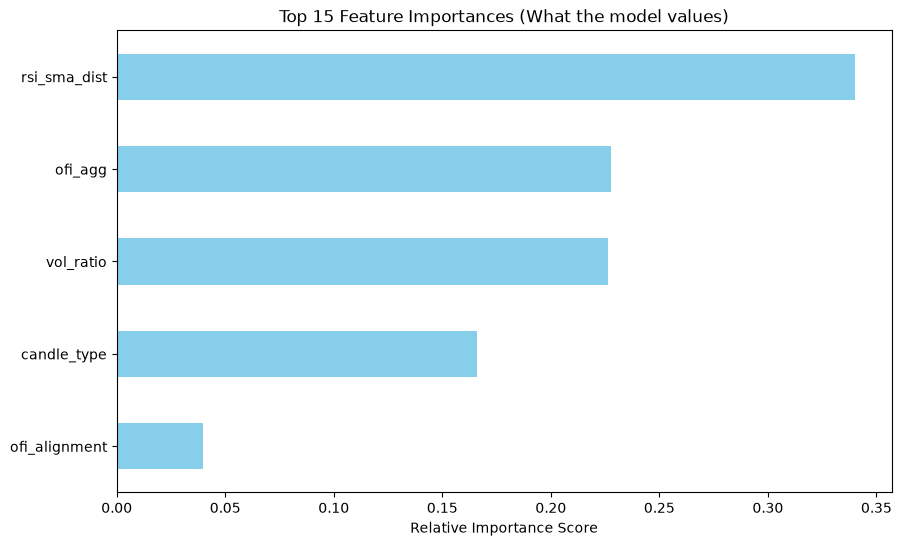

rsi_sma_dist     0.137671
ofi_agg          0.079616
vol_ratio        0.078290
candle_type      0.040420
ofi_alignment    0.000000
dtype: float64


In [18]:

# ─────────────────────────────────────────────────────────────────────────────
# 4 · Evaluate
# ─────────────────────────────────────────────────────────────────────────────
present_classes = sorted(np.unique(np.concatenate([y_tr, y_te])))
present_names   = [CLASS_NAMES[c] for c in present_classes]

y_pred = clf.predict(X_te_s)
proba  = clf.predict_proba(X_te_s)

print("\n── Classification Report ─────────────────────────────────────────")
print(classification_report(y_te, y_pred,
                             labels      = present_classes,
                             target_names= present_names))

cm = confusion_matrix(y_te, y_pred, labels=present_classes)
print("── Confusion Matrix ──────────────────────────────────────────────")
print(pd.DataFrame(cm,
      index   = [f"True  {n}" for n in present_names],
      columns = [f"Pred  {n}" for n in present_names]))

tscv  = TimeSeriesSplit(n_splits=5)
cv_f1 = []
for tr_idx, val_idx in tscv.split(X_tr_s):
    sw_f = compute_sample_weight('balanced', y_tr[tr_idx])
    m = GradientBoostingClassifier(n_estimators=300, max_depth=3,
            learning_rate=0.05, subsample=0.8, min_samples_leaf=5, random_state=42)
    m.fit(X_tr_s[tr_idx], y_tr[tr_idx], sample_weight=sw_f)
    cv_f1.append(f1_score(y_tr[val_idx], m.predict(X_tr_s[val_idx]),
                          labels=present_classes, average='macro'))

print(f"\nWalk-forward macro-F1: {np.mean(cv_f1):.3f} ± {np.std(cv_f1):.3f}")

import matplotlib.pyplot as plt

# 1. Create a Series of importances
feature_importances = pd.Series(clf.feature_importances_, index=FEATS)

# 2. Sort them and take the top 15
top_15 = feature_importances.nlargest(15)

# 3. Plot
plt.figure(figsize=(10, 6))
top_15.plot(kind='barh', color='skyblue')
plt.title("Top 15 Feature Importances (What the model values)")
plt.xlabel("Relative Importance Score")
plt.gca().invert_yaxis() # Highest at the top
plt.show()

from sklearn.feature_selection import mutual_info_classif

# Drop the columns that aren't features
X = feat_df.drop(columns=['target', 'streak_dur'])
y = feat_df['target']

# Calculate MI scores
mi_scores = mutual_info_classif(X, y, discrete_features=False)
mi_series = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)

print(mi_series)

# Conclusion
Model performs terribly and cannot be relied on. RSI-SMA dist variable hasn't been stress tested among different regimes, but its expected to underperform random variable ('vol ratio')
- In a favorable market where RSI_SMA_dist performs well, the model performs decently (not good enough)
![Feature importance + Classification report](./image/img_5.png)
![Mutual Information](./image/img_6.png)
